Question 2: Introductory question. Renamed x to Samples and fs to sample Rate for clarity.

In [64]:
# Import declarations
import os
from scipy.io import wavfile 
import IPython.display as ipd

# Stores the path from the working directory as imperfectSOSPath
noisySOSPath = os.path.join('Data', 'imperfect_sos_cw_700_15_wpm.wav')

# Reads the .wav file and returns the sampleRate and list of individual samples
sampleRate, cleanSamples = wavfile.read(noisySOSPath)

# Displays the audio file as an interactable UI element
ipd.display(ipd.Audio(data=cleanSamples, rate=sampleRate))


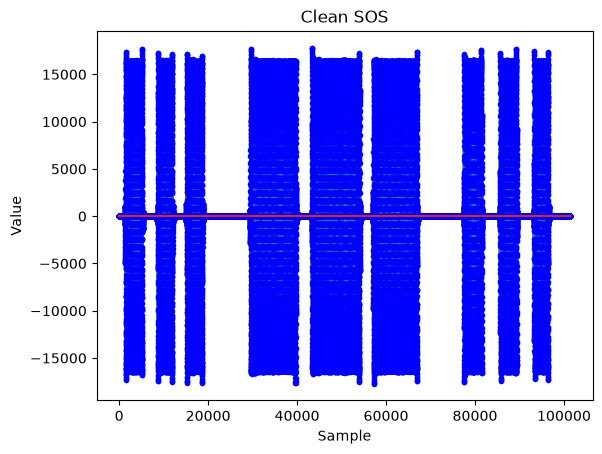

In [65]:
# Import declarations
import matplotlib.pyplot as plt

# Initialize plot
plt.figure()

# Plots markers in a stem plot, b means blue, . means dot marker
plt.stem(cleanSamples, markerfmt='b.')

# Axis Titles
plt.xlabel('Sample')
plt.ylabel('Value')

# Plot Title
plt.title('Clean SOS')

plt.show()

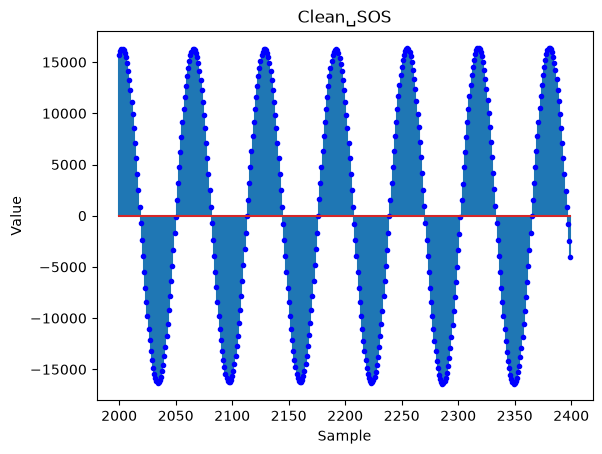

In [66]:
plt.figure()

# Indexes integers from 2000 to 2399
sampleRange = range(2000, 2400)

# Displays samples within the range defined by sampleRange above
plt.stem(sampleRange, cleanSamples[sampleRange],markerfmt='b.')

# Graph and Axis titles
plt.xlabel('Sample')
plt.ylabel('Value')
plt.title('Clean␣SOS')
plt.show()

Question 3.1: Implementing the same procedure to noisy_sos_cw_700_15

In [67]:
# Stores the path from the working directory
noisySOSPath = os.path.join('Data', 'noisy_sos_cw_700_15_wpm.wav')

# Reads the .wav file and returns the sampleRate and list of individual samples
noisySampleRate, noisySamples = wavfile.read(noisySOSPath)

# Displays the audio file as an interactable UI element
ipd.display(ipd.Audio(data=noisySamples, rate=noisySampleRate))


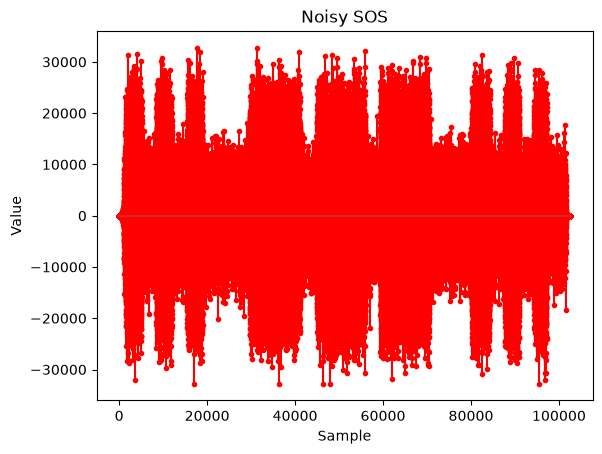

In [68]:
# Initialize plot
plt.figure()

# Plots markers in a stem plot, r means red, . means dot marker
plt.stem(noisySamples, markerfmt='r.', linefmt='r-')

# Axis Titles
plt.xlabel('Sample')
plt.ylabel('Value')

# Plot Title
plt.title('Noisy SOS')

plt.show()

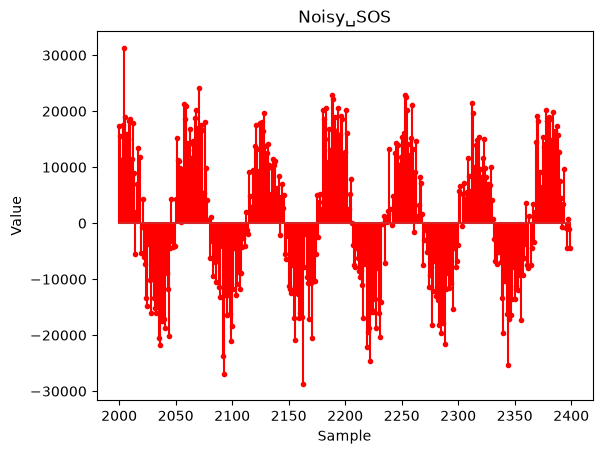

In [69]:
plt.figure()

# Indexes integers from 2000 to 2399
sampleRange = range(2000, 2400)

# Displays samples within the range defined by sampleRange above
plt.stem(sampleRange, noisySamples[sampleRange],markerfmt='r.', linefmt='r-')

# Graph and Axis titles
plt.xlabel('Sample')
plt.ylabel('Value')
plt.title('Noisy␣SOS')
plt.show()

Question 3.2: Imperfect SOS and Noisy SOS both represent an SOS message conveyed in Morse code. However with Noisy SOS there is an element of noise superimposed onto it. While the signal remains audibly recognisable (3 short bursts, followed by 3 long tones followed by another 3 short bursts), the level of clarity still drops as compared to the original message.

This can also be confirmed visually when the waveforms are analyzed. Looking at the shorter range of samples, the sinusoidal nature emerges very well in the clean signal. While there is still a sinusoidal pattern in the noisy signal, it is much more chaotic and irregular.

Question 4.1: Taking into consideration a system which averages 5 consecutive inputs, with equal weighing, would result in an array of 5 elements each being of magnitude 0.2

In [70]:
import numpy as np
import matplotlib.pyplot as plt

# Impulse response 
H = np.ones(5)/5

Question 4.2: This impulse response can be applied to a given input array via convolution, in order to model a moving average filter

In [71]:
from scipy import signal

# Applying H via convolution to input signal X, which in this case is the array noisySamples, gives us the output Signal Y, which is the filtered output.
Y = signal.convolve(noisySamples, H)

# Filtered Audio 
ipd.display(ipd.Audio(data=Y, rate=noisySampleRate))



Question 4.3:

Text(0.5, 1.0, 'Filtered␣Signal')

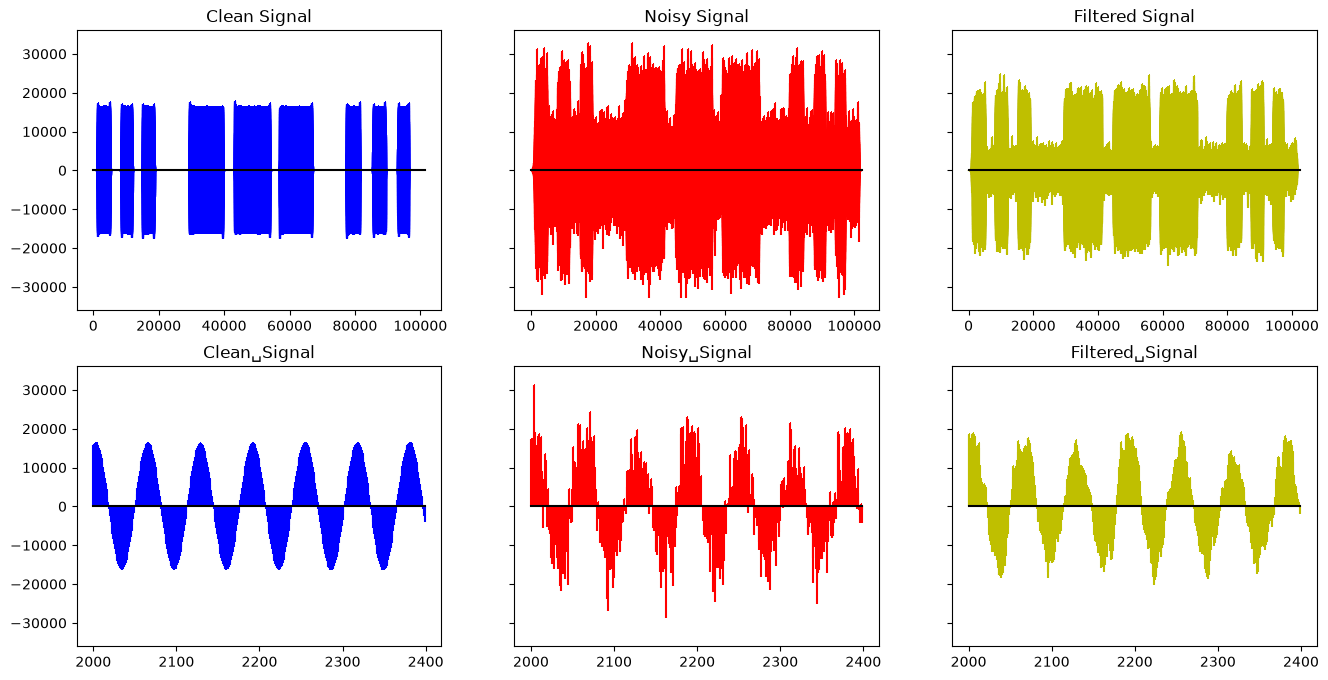

In [72]:
# Plots the Clean, Noisy and filtered signals side by side, alongside their respective shorter ranges 
fig, ax = plt.subplots(2, 3, sharey=True, figsize=(16, 8))

# Note, I opted for a pixel (denoted by ,) marker style for more visual clarity 
ax[0, 0].stem(cleanSamples, markerfmt='b,', linefmt='b-', basefmt='k-')
ax[0, 0].set_title("Clean Signal")

ax[0, 1].stem(noisySamples, markerfmt='r,', linefmt='r-', basefmt='k-')
ax[0, 1].set_title("Noisy Signal")

ax[0, 2].stem(Y, markerfmt='y,', linefmt='y-', basefmt='k-')
ax[0, 2].set_title("Filtered Signal")

ax[1, 0].stem(sampleRange, cleanSamples[sampleRange], markerfmt='b,', linefmt='b-', basefmt='k-')
ax[1, 0].set_title("Clean␣Signal")

ax[1, 1].stem(sampleRange, noisySamples[sampleRange], markerfmt='r,', linefmt='r-', basefmt='k-')
ax[1, 1].set_title("Noisy␣Signal")

ax[1, 2].stem(sampleRange, Y[sampleRange], markerfmt='y,', linefmt='y-', basefmt='k-')
ax[1, 2].set_title("Filtered␣Signal")



Observations:
Looking at the 3 signals side by side, the differences between all of them are immediately discernable. The clean signal can be taken as a reference with respect to the Noisy and Filtered signals. Both visually and audibly, the clean signal conveys the SOS signal (3 short bursts, 3 long bursts, 3 short bursts) with consistent amplitudes and no underlying noise whatsoever. The shorter sample range is also seen to convey a very characteristic sinusoidal waveform.

While this pattern is also present at a glance in the noisy signal, both visually and audibly the noise is very pronounced. With comparison to the clean signal, it can also be seen that the noise is consistent throughout the whole signal, as the amplitudes of the 'beeps' are seen to be almost double in magnitude. The noise is also seen to be fairly random in nature, evident by the erratic jags and dips that can be seen between neighbouring samples. Something of note is also seen with the previously silent gaps present in the clean signal, which are now also occupied by noise. This suggests that the noise is not just simply a random scaling transformation applied to the clean signal, but a random value within a certain range that is added on top of the original signal.

Finally, looking at the filtered signal, the jaggedness is seen to be significantly reduced when compared to the noisy signal. Considering that the filter applied is at its core, averaging out the amplitudes of the signal 5 samples at a time, the waveform correlates to the idea well. While overall the curve can still be seen to retain an element of jaggedness, looking at individual, neighbouring samples, a much smoother gradient is observed. The extreme, outlier values are also absent in the filtered signal. Something to note however, is that the silent gaps present in the clean signal are still not seen in the filtered signal. While a decrease in amplitude is observed from the noisy signal, since the filter takes the average of neighbouring signals, it is not possible to reduce the noise to zero. This observation is confirmed audibly as well, with an overall decrease in volume and the background noise being mellower as compared to the noisy signal.

Question 4.4: Same filter with moving window length n=10:

Text(0.5, 1.0, 'Filtered␣Signal (n=10)')

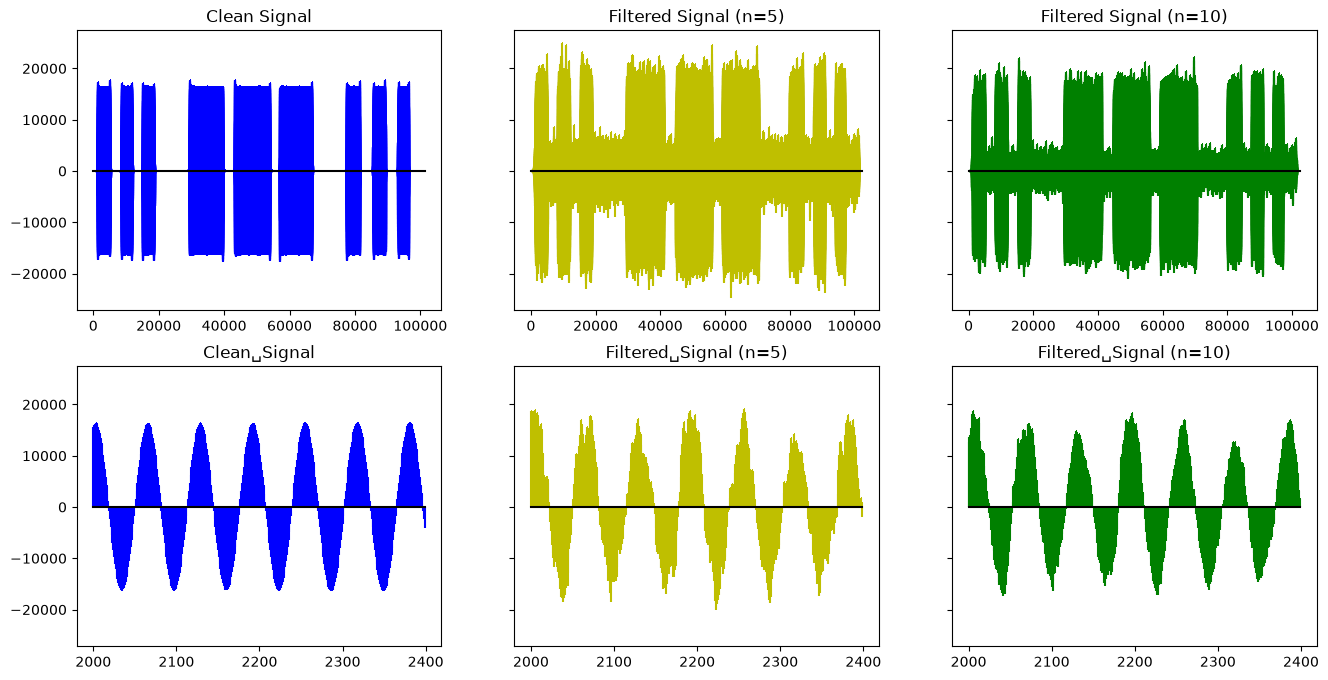

In [75]:
# Impulse Response for n=10
H = np.ones(10)/10

# Applying Convolution
Z = signal.convolve(noisySamples, H)

# Filtered Audio 
ipd.display(ipd.Audio(data=Z, rate=noisySampleRate))

# Plots the Clean, Noisy and filtered signals side by side, alongside their respective shorter ranges 
fig, ax = plt.subplots(2, 3, sharey=True, figsize=(16, 8))

# Note, I opted for a pixel (denoted by ,) marker style for more visual clarity 
ax[0, 0].stem(cleanSamples, markerfmt='b,', linefmt='b-', basefmt='k-')
ax[0, 0].set_title("Clean Signal")

ax[0, 1].stem(Y, markerfmt='y,', linefmt='y-', basefmt='k-')
ax[0, 1].set_title("Filtered Signal (n=5)")

ax[0, 2].stem(Z, markerfmt='g,', linefmt='g-', basefmt='k-')
ax[0, 2].set_title("Filtered Signal (n=10)")

ax[1, 0].stem(sampleRange, cleanSamples[sampleRange], markerfmt='b,', linefmt='b-', basefmt='k-')
ax[1, 0].set_title("Clean␣Signal")

ax[1, 1].stem(sampleRange, Y[sampleRange], markerfmt='y,', linefmt='y-', basefmt='k-')
ax[1, 1].set_title("Filtered␣Signal (n=5)")

ax[1, 2].stem(sampleRange, Z[sampleRange], markerfmt='g,', linefmt='g-', basefmt='k-')
ax[1, 2].set_title("Filtered␣Signal (n=10)")

Comments go here

In [76]:
# Impulse Responses Ranging from n=15 to n=30 in steps of 5
H15 = np.ones(15)/15
H20 = np.ones(20)/20
H25 = np.ones(25)/25
H30 = np.ones(30)/30

# Applying each filter to the noisy signal
Y15 = signal.convolve(noisySamples, H15)
Y20 = signal.convolve(noisySamples, H20)
Y25 = signal.convolve(noisySamples, H25)
Y30 = signal.convolve(noisySamples, H30)

# Filtered Audio in order from Y15 to Y30
ipd.display(ipd.Audio(data=Y15, rate=noisySampleRate))
ipd.display(ipd.Audio(data=Y20, rate=noisySampleRate))
ipd.display(ipd.Audio(data=Y25, rate=noisySampleRate))
ipd.display(ipd.Audio(data=Y30, rate=noisySampleRate))

Text(0.5, 1.0, 'Y30')

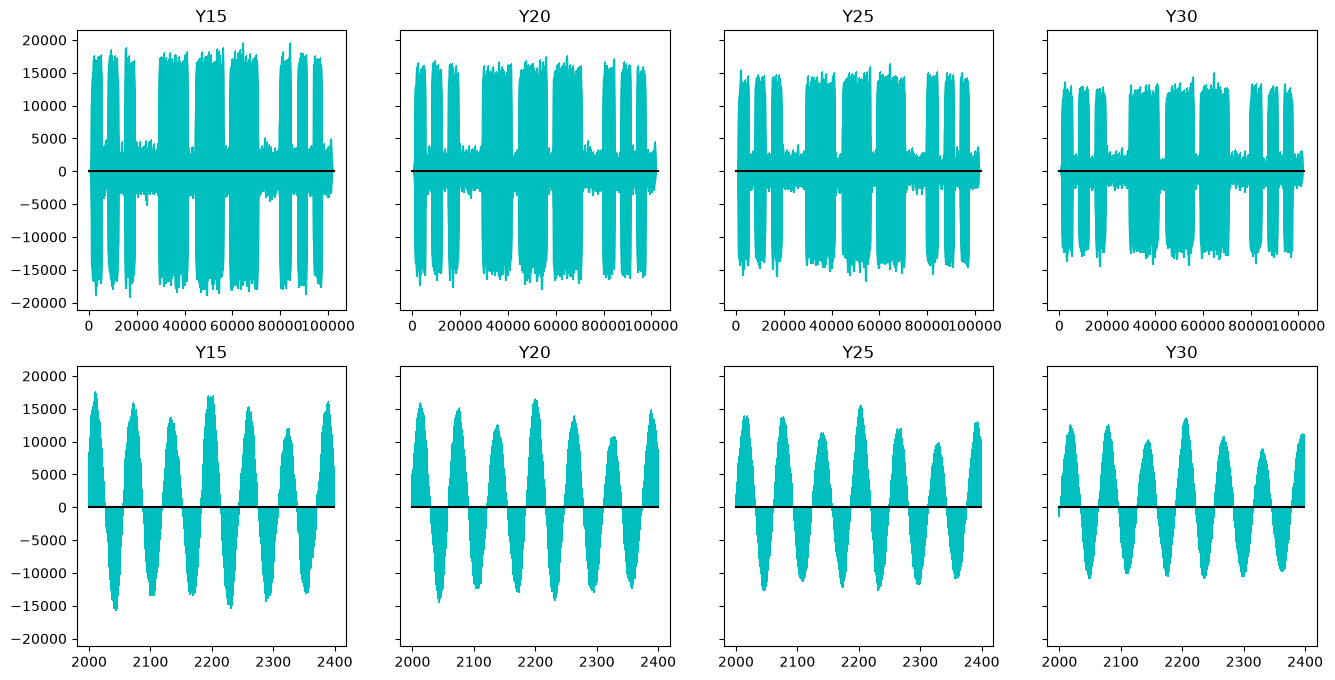

In [78]:
# Plots of Y15 to Y30 plotted side by side 
fig, ax = plt.subplots(2, 4, sharey=True, figsize=(16, 8))

ax[0, 0].stem(Y15, markerfmt='c,', linefmt='c-', basefmt='k-')
ax[0, 0].set_title("Y15")

ax[0, 1].stem(Y20, markerfmt='c,', linefmt='c-', basefmt='k-')
ax[0, 1].set_title("Y20")

ax[0, 2].stem(Y25, markerfmt='c,', linefmt='c-', basefmt='k-')
ax[0, 2].set_title("Y25")

ax[0, 3].stem(Y30, markerfmt='c,', linefmt='c-', basefmt='k-')
ax[0, 3].set_title("Y30")

ax[1, 0].stem(sampleRange, Y15[sampleRange], markerfmt='c,', linefmt='c-', basefmt='k-')
ax[1, 0].set_title("Y15")

ax[1, 1].stem(sampleRange, Y20[sampleRange], markerfmt='c,', linefmt='c-', basefmt='k-')
ax[1, 1].set_title("Y20")

ax[1, 2].stem(sampleRange, Y25[sampleRange], markerfmt='c,', linefmt='c-', basefmt='k-')
ax[1, 2].set_title("Y25")

ax[1, 3].stem(sampleRange, Y30[sampleRange], markerfmt='c,', linefmt='c-', basefmt='k-')
ax[1, 3].set_title("Y30")